In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
# Part 0 — Shared Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

rng = np.random.default_rng(42)
n = 500

df = pd.DataFrame({
    "demand": rng.integers(50, 151, n),
    "supply": rng.integers(45, 141, n),
    "distance_km": rng.uniform(1, 15, n).round(1),
    "peak": rng.choice(
        ["Yes", "No"], n, p=[0.45, 0.55]
    ),
    "weather": rng.choice(
        ["Clear", "Rain"], n, p=[0.75, 0.25]
    )
})

noise = rng.normal(0, 1.7, n)

df["wait_min"] = (
    8
    + 0.12 * (df["demand"] - 100)
    - 0.09 * (df["supply"] - 90)
    + 0.25 * (df["distance_km"] - 7)
    + 1.5 * (df["peak"] == "Yes")
    + 2.0 * (df["weather"] == "Rain")
    + noise
).clip(lower=0.5).round(2)

df["late"] = (df["wait_min"] >= 10).astype(int)

display(df.head())

,demand,supply,distance_km,peak,weather,wait_min,late
0,59,55,11.3,Yes,Clear,7.06,0
1,128,107,13.4,No,Rain,14.97,1
2,116,137,13.9,Yes,Clear,6.87,0
3,94,128,8.1,Yes,Clear,5.15,0
4,93,71,8.3,No,Rain,10.20,1


# Research question: Will a passenger wait at least 10 minutes?

$Y=
\begin{cases}
1,&\text{if wait\_min}\ge10\\
0,&\text{otherwise}
\end{cases}$



$\log\left(\frac{p}{1-p}\right)
=\beta_0+\beta_1x_1+\cdots+\beta_kx_k$

$p=P(\text{Late}=1\mid X)$

In [3]:
# Task 1 — Train Logistic Regression

train_log, test_log = train_test_split(
    df,
    test_size=0.25,
    random_state=42,
    stratify=df["late"]
)

logit_model = smf.logit(
    formula="""
        late ~
        demand +
        supply +
        distance_km +
        C(peak) +
        C(weather)
    """,
    data=train_log
).fit()

print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.217461
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                   late   No. Observations:                  375
Model:                          Logit   Df Residuals:                      369
Method:                           MLE   Df Model:                            5
Date:                Wed, 04 Nov 2026   Pseudo R-squ.:                  0.6805
Time:                        12:46:09   Log-Likelihood:                -81.548
converged:                       True   LL-Null:                       -255.27
Covariance Type:            nonrobust   LLR p-value:                 6.217e-73
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -9.4413      1.456     -6.483      0.000     -12.296      -6.587
C(pea

In [4]:
# Task 2 — Interpret coefficients, p-values and odds ratios

print("Coefficients:")
print(logit_model.params)

print("\nP-values:")
print(logit_model.pvalues)

# Convert log-odds coefficients to odds ratios
odds_ratios = np.exp(logit_model.params)

print("\nOdds Ratios:")
print(odds_ratios)

print("\n95% CI for Odds Ratios:")
print(np.exp(logit_model.conf_int()))

Coefficients:
Intercept            -9.441314
C(peak)[T.Yes]        1.282718
C(weather)[T.Rain]    2.739213
demand                0.138466
supply               -0.100887
distance_km           0.306512
dtype: float64

P-values:
Intercept             8.985981e-11
C(peak)[T.Yes]        3.358505e-03
C(weather)[T.Rain]    2.370848e-07
demand                5.983672e-17
supply                4.932424e-14
distance_km           4.651898e-07
dtype: float64

Odds Ratios:
Intercept              0.000079
C(peak)[T.Yes]         3.606427
C(weather)[T.Rain]    15.474804
demand                 1.148510
supply                 0.904035
distance_km            1.358678
dtype: float64

95% CI for Odds Ratios:
                           0          1
Intercept           0.000005   0.001378
C(peak)[T.Yes]      1.530367   8.498820
C(weather)[T.Rain]  5.475544  43.734387
demand              1.111849   1.186380
supply              0.880616   0.928077
distance_km         1.206011   1.530671


In [5]:
# Task 3 — Predict probabilities and classes

# Statsmodels Logit directly predicts probabilities
y_prob = logit_model.predict(test_log)

# Classification threshold = 0.5
y_pred = (y_prob >= 0.5).astype(int)

results = pd.DataFrame({
    "Actual": test_log["late"],
    "Probability": y_prob,
    "Prediction": y_pred
})

display(results.head(10))

,Actual,Probability,Prediction
312,0,0.000619,0
488,1,0.996983,1
177,0,0.128443,0
371,0,0.637002,1
2,0,0.160081,0
315,0,0.139236,0
96,0,0.009098,0
322,1,0.955268,1
219,1,0.999733,1
111,1,0.998425,1


Text(0.5, 1.0, 'Statsmodels Logistic Regression')

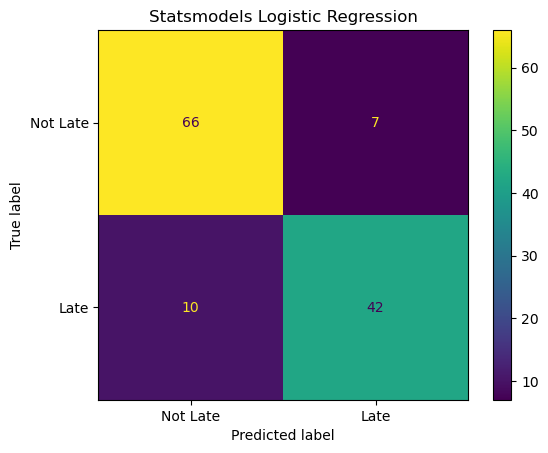

Accuracy: 0.864
Precision: 0.8571428571428571
Recall: 0.8076923076923077


In [6]:
# Task 4 — Confusion matrix and classification metrics

cm = confusion_matrix(
    test_log["late"],
    y_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Late", "Late"]
).plot()

plt.title("Statsmodels Logistic Regression")
plt.show()

print("Accuracy:",
      accuracy_score(test_log["late"], y_pred))

print("Precision:",
      precision_score(test_log["late"], y_pred))

print("Recall:",
      recall_score(test_log["late"], y_pred))

In [7]:
# Task 5 — Classification threshold analysis

comparison = []

for threshold in [0.3, 0.5, 0.7]:

    predictions = (
        y_prob >= threshold
    ).astype(int)

    comparison.append({
        "Threshold": threshold,
        "Precision": precision_score(
            test_log["late"], predictions
        ),
        "Recall": recall_score(
            test_log["late"], predictions
        )
    })

display(pd.DataFrame(comparison).round(3))

# question: If the company wants to detect as many potentially late trips as possible, 
# which threshold should it choose among these three? Explain the trade-off.

,Threshold,Precision,Recall
0,0.3,0.810,0.904
1,0.5,0.857,0.808
2,0.7,0.929,0.750


ROC AUC: 0.950


Text(0.5, 1.0, 'Logistic Regression — ROC Curve')

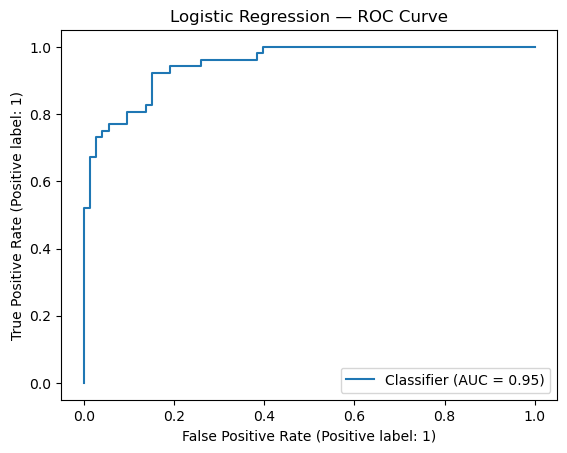

In [8]:
# Task 6 — ROC AUC

auc = roc_auc_score(
    test_log["late"],
    y_prob
)

print(f"ROC AUC: {auc:.3f}")

RocCurveDisplay.from_predictions(
    test_log["late"],
    y_prob
)

plt.title("Logistic Regression — ROC Curve")
plt.show()

In [9]:
# Task 7 — Predict a new ride request

new_trip = pd.DataFrame({
    "demand": [125],
    "supply": [65],
    "distance_km": [8.0],
    "peak": ["Yes"],
    "weather": ["Rain"]
})

p_late = logit_model.predict(new_trip).iloc[0]

print(f"P(Late): {p_late:.4f}")

print(
    "Prediction:",
    "Late" if p_late >= 0.5 else "Not Late"
)

P(Late): 0.9996
Prediction: Late
